# The Issue of Credit Assessment

##### The answers to the requested exercises begin in Section 21, Cell 59, and have been provided based on pre-existing data.

## 1. Import libraries

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.feature_selection import mutual_info_classif
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, precision_recall_fscore_support,
                             recall_score, f1_score, roc_auc_score, average_precision_score)


pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

print("Libraries imported successfully.")

Libraries imported successfully.


In [68]:
import itertools
import time
import warnings
warnings.filterwarnings("ignore")

from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedKFold, cross_validate

import sklearn
pd.set_option("display.max_colwidth", None)          

try:
    from imblearn.pipeline import Pipeline            
    from imblearn import FunctionSampler
    from imblearn.over_sampling import SMOTENC
except ImportError as e:
    raise ImportError("Install the package first:  pip install imbalanced-learn") from e

import imblearn

## 2. Load the data

In [ ]:
path_train ="GiveMeSomeCredit.csv"

data= pd.read_csv(path_train)

print("shape", data.shape)
data.head(10)

shape (149724, 14)


,SeriousDlqin,RevolvingUtilizationOfUnsecuredLines,age,SEX,EDUCATION,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents,NumberOfDefault
0,1,0.878881,40,F,3,0,0.605616,12000.0,19,2,3,11,0.0,1
1,0,1.000000,34,F,1,3,2121.000000,0.0,9,0,2,9,2.0,0
2,0,0.470085,59,F,1,5,1.280078,15916.0,34,6,14,8,0.0,0
3,1,0.908082,26,M,3,3,1.444855,6500.0,22,1,4,8,0.0,2
4,1,1.000000,36,M,3,4,0.913676,2200.0,10,1,1,7,1.0,1
5,1,1.459344,54,F,3,3,1718.000000,NaN,18,9,0,7,0.0,2
6,1,14.540918,45,F,3,3,1.151865,3726.0,11,0,2,7,3.0,3
7,1,0.915053,48,M,2,1,0.652057,2600.0,8,0,1,7,0.0,3
8,1,1.000000,31,F,2,0,503.000000,NaN,4,7,0,7,0.0,2
9,0,1.445042,38,F,3,0,0.136132,4715.0,5,3,0,7,2.0,0


In [5]:
df=data.copy()

## 3. Understand the structure


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 149724 entries, 0 to 149723
Data columns (total 14 columns):
 #   Column                                Non-Null Count   Dtype  
---  ------                                --------------   -----  
 0   SeriousDlqin                          149724 non-null  int64  
 1   RevolvingUtilizationOfUnsecuredLines  149724 non-null  float64
 2   age                                   149724 non-null  int64  
 3   SEX                                   149724 non-null  object 
 4   EDUCATION                             149724 non-null  int64  
 5   NumberOfTime30-59DaysPastDueNotWorse  149724 non-null  int64  
 6   DebtRatio                             149724 non-null  float64
 7   MonthlyIncome                         120117 non-null  float64
 8   NumberOfOpenCreditLinesAndLoans       149724 non-null  int64  
 9   NumberOfTimes90DaysLate               149724 non-null  int64  
 10  NumberRealEstateLoansOrLines          149724 non-null  int64  
 11  

In [7]:
df["SEX"] = df["SEX"].map({
    "M": 0,
    "F": 1
})

In [8]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 149724
Number of columns: 14


## 4. Define the target


In [9]:
target = "SeriousDlqin"

print("Target:", target)
print("Unique values:")
print(df[target].unique())

Target: SeriousDlqin
Unique values:
[1 0]


In [10]:
target_summary = pd.DataFrame({
    "Count": df[target].value_counts(),
    "Percent": df[target].value_counts(normalize=True).mul(100).round(2)
})

target_summary

,Count,Percent
SeriousDlqin,,
0,139845,93.4
1,9879,6.6


## 5. Duplicate rows

In [11]:
duplicate_count = df.duplicated().sum()

print("Number of duplicated rows:", duplicate_count)


Number of duplicated rows: 142


In [12]:
df[df.duplicated(keep=False)]


,SeriousDlqin,RevolvingUtilizationOfUnsecuredLines,age,SEX,EDUCATION,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents,NumberOfDefault
30045,0,1.0,32,1,3,0,0.0,NaN,0,1,0,0,0.0,0
30050,0,1.0,32,1,3,0,0.0,NaN,0,1,0,0,0.0,0
30067,0,1.0,37,1,3,0,0.0,NaN,0,1,0,0,0.0,0
30070,0,1.0,37,1,3,0,0.0,NaN,0,1,0,0,0.0,0
121347,0,1.0,22,1,1,0,0.0,929.0,1,0,0,0,0.0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
149706,0,0.0,42,0,3,0,0.0,NaN,2,0,0,0,0.0,0
149709,0,0.0,79,1,3,0,0.0,NaN,1,0,0,0,NaN,0
149714,0,0.0,23,1,2,0,0.0,NaN,2,0,0,0,0.0,0
149717,0,0.0,59,1,1,0,0.0,NaN,1,0,0,0,0.0,0


## 6. Linear Correlation

In [13]:
corr = df.corr()

corr[target].sort_values(ascending=False)

SeriousDlqin                            1.000000
NumberOfDefault                         0.921535
NumberOfTimes90DaysLate                 0.314557
NumberOfTime30-59DaysPastDueNotWorse    0.274554
NumberOfTime60-89DaysPastDueNotWorse    0.268128
NumberOfDependents                      0.047442
EDUCATION                               0.002214
RevolvingUtilizationOfUnsecuredLines   -0.001625
SEX                                    -0.002724
NumberRealEstateLoansOrLines           -0.003895
DebtRatio                              -0.008778
MonthlyIncome                          -0.023343
NumberOfOpenCreditLinesAndLoans        -0.024219
age                                    -0.112966
Name: SeriousDlqin, dtype: float64

## 7. Target Leakage

In [14]:
print(df[["NumberOfDefault", target]].head(20))


    NumberOfDefault  SeriousDlqin
0                 1             1
1                 0             0
2                 0             0
3                 2             1
4                 1             1
5                 2             1
6                 3             1
7                 3             1
8                 2             1
9                 0             0
10                0             0
11                0             0
12                0             0
13                0             0
14                3             1
15                1             1
16                2             1
17                0             0
18                2             1
19                2             1


In [15]:
df = df.drop(columns=["NumberOfDefault"])

print("Leaked feature removed.")

Leaked feature removed.


## 8. Data validation: impossible value


In [16]:
print("Age < 18:", (df["age"] < 18).sum())
print("Age > 100:", (df["age"] > 100).sum())
print("MonthlyIncome < 0:", (df["MonthlyIncome"] < 0).sum())
print("NumberOfTimes90DaysLate < 0:", (df["NumberOfTimes90DaysLate"] < 0).sum())
print("NumberRealEstateLoansOrLines < 0:", (df["NumberRealEstateLoansOrLines"] < 0).sum())

Age < 18: 1
Age > 100: 13
MonthlyIncome < 0: 0
NumberOfTimes90DaysLate < 0: 0
NumberRealEstateLoansOrLines < 0: 0


In [17]:
df = df[(df["age"] >= 18) & (df["age"] <= 100)]

## 9. Train-Test Split

In [18]:
X = df.drop(columns=[target])
y = df[target]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

X_train: (104797, 12)
X_test : (44913, 12)
y_train: (104797,)
y_test : (44913,)


In [19]:
print("Overall:")
print(y.value_counts(normalize=True).mul(100).round(2))

print("\nTrain:")
print(y_train.value_counts(normalize=True).mul(100).round(2))

print("\nTest:")
print(y_test.value_counts(normalize=True).mul(100).round(2))

Overall:
SeriousDlqin
0    93.4
1     6.6
Name: proportion, dtype: float64

Train:
SeriousDlqin
0    93.4
1     6.6
Name: proportion, dtype: float64

Test:
SeriousDlqin
0    93.4
1     6.6
Name: proportion, dtype: float64


In [20]:
train_df = X_train.copy()
train_df[target] = y_train

print("Train dataframe shape:", train_df.shape)
train_df.head()

Train dataframe shape: (104797, 13)


,RevolvingUtilizationOfUnsecuredLines,age,SEX,EDUCATION,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents,SeriousDlqin
134668,0.203223,60,1,2,0,1600.000000,NaN,8,0,1,0,0.0,0
119703,1.000000,24,0,3,0,0.100074,1358.0,3,0,0,0,0.0,0
37115,0.200152,49,0,1,0,0.224416,12917.0,8,0,1,0,0.0,0
141624,0.025735,78,1,1,0,347.000000,NaN,7,0,0,0,0.0,0
139483,0.133169,29,0,3,0,723.000000,NaN,5,0,0,0,0.0,0


In [21]:
test_df = X_test.copy()
test_df[target] = y_test

print("Train dataframe shape:", test_df.shape)
test_df.head()

Train dataframe shape: (44913, 13)


,RevolvingUtilizationOfUnsecuredLines,age,SEX,EDUCATION,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents,SeriousDlqin
76820,0.021663,61,1,3,0,0.500453,5516.0,8,0,2,0,0.0,0
135401,0.000000,62,1,3,0,1461.000000,NaN,14,0,1,0,0.0,0
5324,0.060561,39,1,3,0,0.198144,12500.0,8,0,1,1,2.0,0
90486,0.824374,30,0,2,0,0.100439,4330.0,4,0,0,0,0.0,0
43461,1.000000,41,1,1,0,0.023712,10500.0,1,0,1,0,2.0,1


## 10. Missing value

In [22]:
missing_train = pd.DataFrame({
    "Missing_Count": train_df.isnull().sum(),
    "Missing_Percent": (
        train_df.isnull().mean().mul(100).round(2)
    )
})

missing_train = missing_train.sort_values(
    "Missing_Percent",
    ascending=False
)

missing_train

,Missing_Count,Missing_Percent
MonthlyIncome,20723,19.77
NumberOfDependents,2767,2.64
RevolvingUtilizationOfUnsecuredLines,0,0.00
age,0,0.00
SEX,0,0.00
EDUCATION,0,0.00
NumberOfTime30-59DaysPastDueNotWorse,0,0.00
DebtRatio,0,0.00
NumberOfOpenCreditLinesAndLoans,0,0.00
NumberOfTimes90DaysLate,0,0.00


In [23]:
train_df.groupby(
    train_df["MonthlyIncome"].isna()
)["SeriousDlqin"].mean()

MonthlyIncome
False    0.068761
True     0.054722
Name: SeriousDlqin, dtype: float64

In [24]:
train_df.groupby(
    train_df["NumberOfDependents"].isna()
)["SeriousDlqin"].mean()

NumberOfDependents
False    0.066627
True     0.042284
Name: SeriousDlqin, dtype: float64

In [25]:
# Missing values in Test
missing_test = pd.DataFrame({
    "Missing_Count": test_df.isnull().sum(),
    "Missing_Percent": test_df.isnull().mean().mul(100).round(2)
})

missing_test = missing_test.sort_values(
    "Missing_Percent",
    ascending=False
)

missing_test

,Missing_Count,Missing_Percent
MonthlyIncome,8877,19.76
NumberOfDependents,1123,2.50
RevolvingUtilizationOfUnsecuredLines,0,0.00
age,0,0.00
SEX,0,0.00
EDUCATION,0,0.00
NumberOfTime30-59DaysPastDueNotWorse,0,0.00
DebtRatio,0,0.00
NumberOfOpenCreditLinesAndLoans,0,0.00
NumberOfTimes90DaysLate,0,0.00


In [26]:
# Train
train_df["MonthlyIncome_missing"] = (
    train_df["MonthlyIncome"].isna().astype(int)
)

# Test
test_df["MonthlyIncome_missing"] = (
    test_df["MonthlyIncome"].isna().astype(int)
)

In [27]:
income_median = train_df["MonthlyIncome"].median()

train_df["MonthlyIncome"] = train_df["MonthlyIncome"].fillna(
    income_median
)

test_df["MonthlyIncome"] = test_df["MonthlyIncome"].fillna(
    income_median
)

In [28]:
dependents_median = train_df["NumberOfDependents"].median()

train_df["NumberOfDependents"] = train_df[
    "NumberOfDependents"
].fillna(dependents_median)

test_df["NumberOfDependents"] = test_df[
    "NumberOfDependents"
].fillna(dependents_median)

 ## 11. Outlier analysis

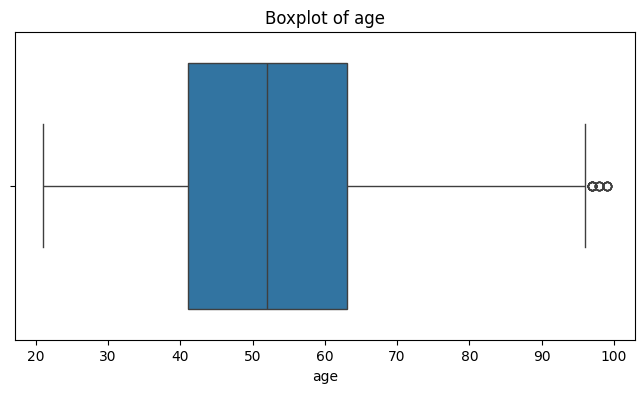

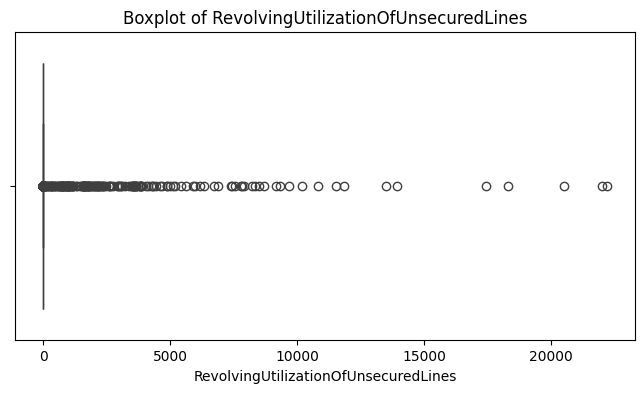

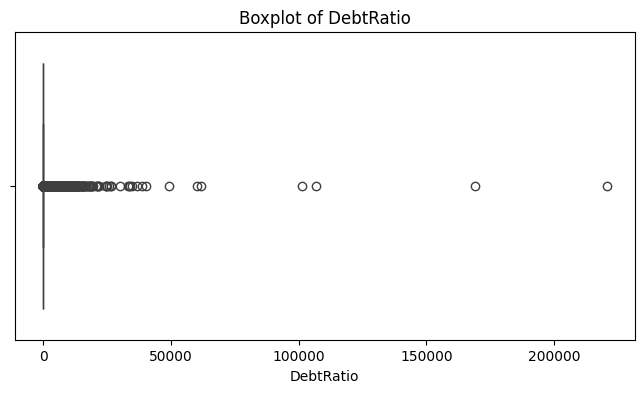

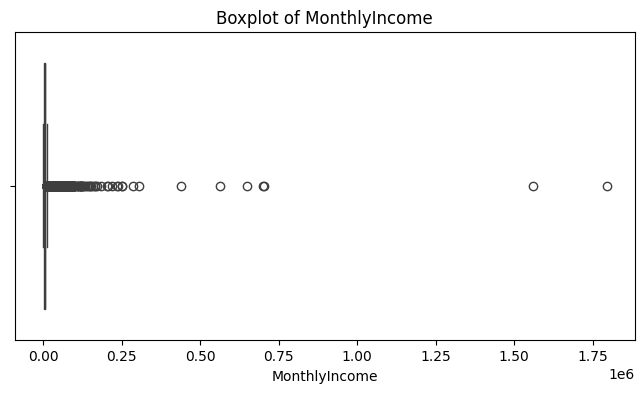

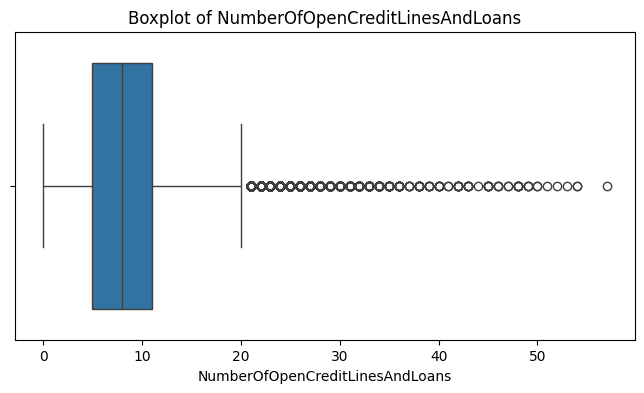

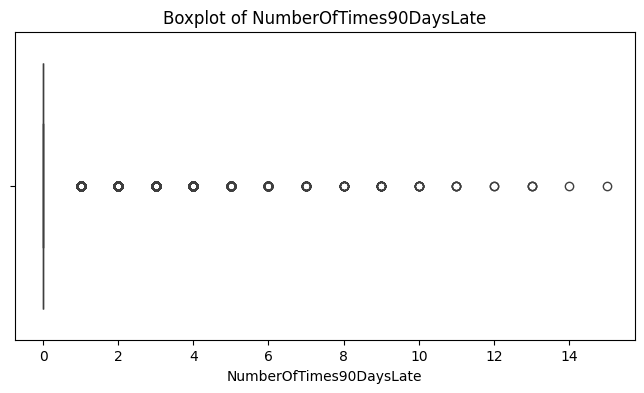

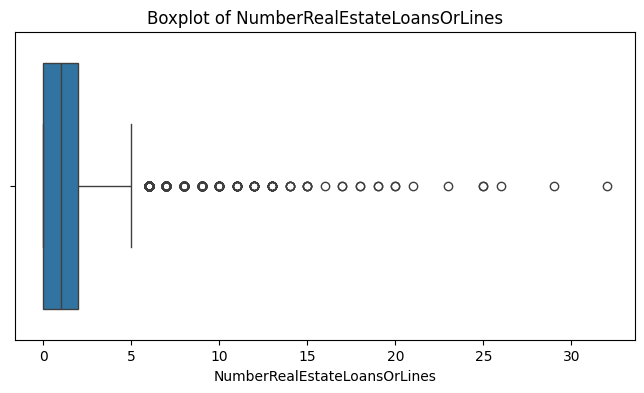

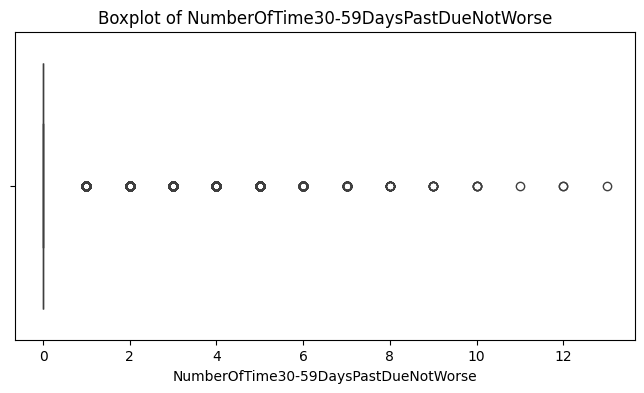

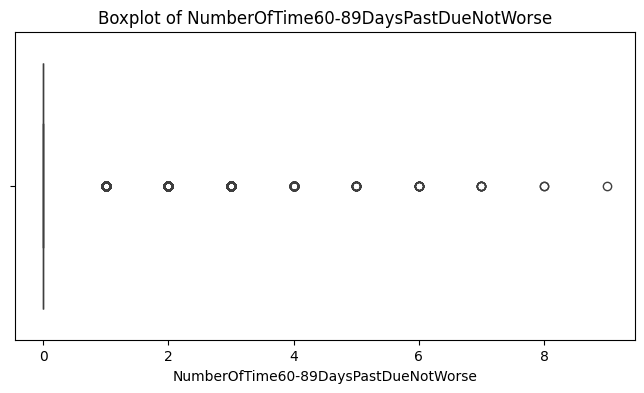

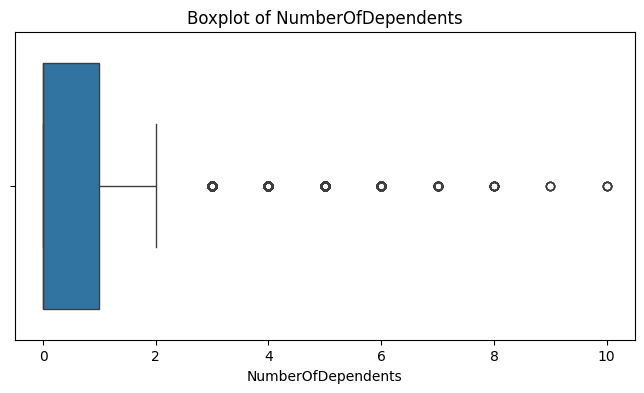

In [29]:
numeric_columns = [
    "age",
    "RevolvingUtilizationOfUnsecuredLines",
    "DebtRatio",
    "MonthlyIncome",
    "NumberOfOpenCreditLinesAndLoans",
    "NumberOfTimes90DaysLate",
    "NumberRealEstateLoansOrLines",
    "NumberOfTime30-59DaysPastDueNotWorse",
    "NumberOfTime60-89DaysPastDueNotWorse",
    "NumberOfDependents"
]

for col in numeric_columns:
    plt.figure(figsize=(8, 4))
    sns.boxplot(x=train_df[col])
    plt.title(f"Boxplot of {col}")
    plt.show()

In [30]:
numeric_cols = [
    "age",
    "RevolvingUtilizationOfUnsecuredLines",
    "DebtRatio",
    "MonthlyIncome",
    "NumberOfOpenCreditLinesAndLoans",
    "NumberOfTimes90DaysLate",
    "NumberRealEstateLoansOrLines",
    "NumberOfTime30-59DaysPastDueNotWorse",
    "NumberOfTime60-89DaysPastDueNotWorse",
    "NumberOfDependents"
]

train_df["Is_Outlier"] = False

outlier_report = []

for col in numeric_cols:
    q1 = train_df[col].quantile(0.25)
    q3 = train_df[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    col_outlier = (
        (train_df[col] < lower) |
        (train_df[col] > upper)
    )

    train_df["Is_Outlier"] = (
        train_df["Is_Outlier"] |
        col_outlier
    )

    count = ((train_df[col] < lower) | (train_df[col] > upper)).sum()

    outlier_report.append({
        "Feature": col,
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "Lower_Bound": lower,
        "Upper_Bound": upper,
        "Candidate_Outliers": count,
        "Outlier_Percent": round(count / len(train_df) * 100, 2)
    })

outlier_report = pd.DataFrame(outlier_report)
outlier_report.sort_values("Outlier_Percent", ascending=False)

,Feature,Q1,Q3,IQR,Lower_Bound,Upper_Bound,Candidate_Outliers,Outlier_Percent
2,DebtRatio,0.175977,0.864820,0.688843,-0.857287,1.898084,21865,20.86
7,NumberOfTime30-59DaysPastDueNotWorse,0.000000,0.000000,0.000000,0.000000,0.000000,16510,15.75
9,NumberOfDependents,0.000000,1.000000,1.000000,-1.500000,2.500000,9337,8.91
3,MonthlyIncome,3923.000000,7420.000000,3497.000000,-1322.500000,12665.500000,6367,6.08
5,NumberOfTimes90DaysLate,0.000000,0.000000,0.000000,0.000000,0.000000,5652,5.39
8,NumberOfTime60-89DaysPastDueNotWorse,0.000000,0.000000,0.000000,0.000000,0.000000,5134,4.90
4,NumberOfOpenCreditLinesAndLoans,5.000000,11.000000,6.000000,-4.000000,20.000000,2752,2.63
1,RevolvingUtilizationOfUnsecuredLines,0.029924,0.555344,0.525421,-0.758207,1.343475,542,0.52
6,NumberRealEstateLoansOrLines,0.000000,2.000000,2.000000,-3.000000,5.000000,543,0.52
0,age,41.000000,63.000000,22.000000,8.000000,96.000000,21,0.02


In [31]:
outlier_distribution = (
    train_df[train_df["Is_Outlier"]]["SeriousDlqin"]
    .value_counts()
    .sort_index()
)

print(outlier_distribution)

SeriousDlqin
0    45783
1     5424
Name: count, dtype: int64


## 12. Univariate relationship with target


In [32]:
features_to_compare = [
    "age",
    "RevolvingUtilizationOfUnsecuredLines",
    "DebtRatio",
    "MonthlyIncome",
    "NumberOfOpenCreditLinesAndLoans",
    "NumberOfTimes90DaysLate",
    "NumberRealEstateLoansOrLines",
    "NumberOfTime30-59DaysPastDueNotWorse",
    "NumberOfTime60-89DaysPastDueNotWorse",
    "NumberOfDependents"
]

train_df.groupby(target)[features_to_compare].mean().T

SeriousDlqin,0,1
age,52.785190,46.061171
RevolvingUtilizationOfUnsecuredLines,6.185745,6.001989
DebtRatio,352.223284,305.816230
MonthlyIncome,6447.125958,5644.865076
NumberOfOpenCreditLinesAndLoans,8.502452,7.946638
NumberOfTimes90DaysLate,0.049723,0.672451
NumberRealEstateLoansOrLines,1.021179,0.993926
NumberOfTime30-59DaysPastDueNotWorse,0.192936,0.977440
NumberOfTime60-89DaysPastDueNotWorse,0.041192,0.402025
NumberOfDependents,0.724372,0.941287


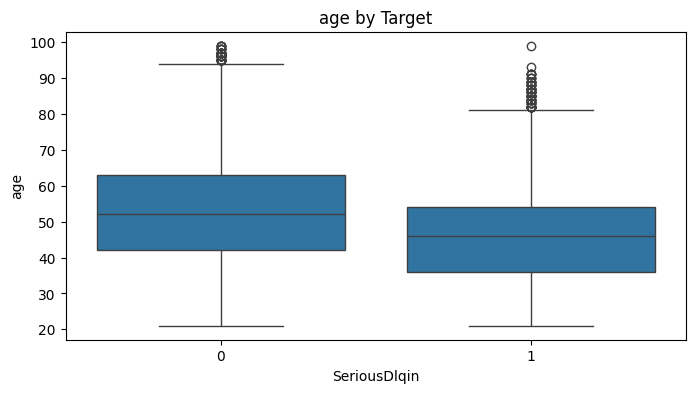

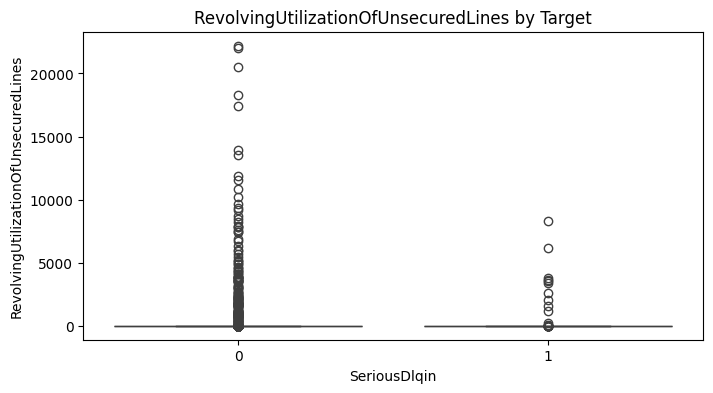

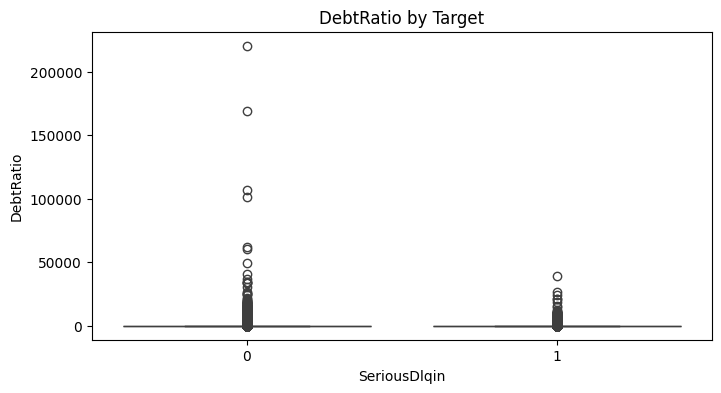

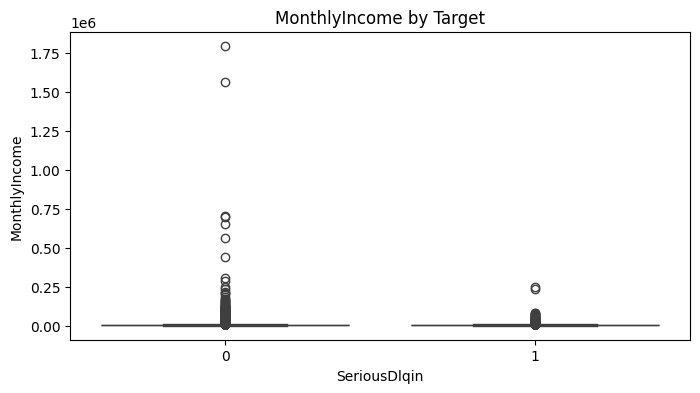

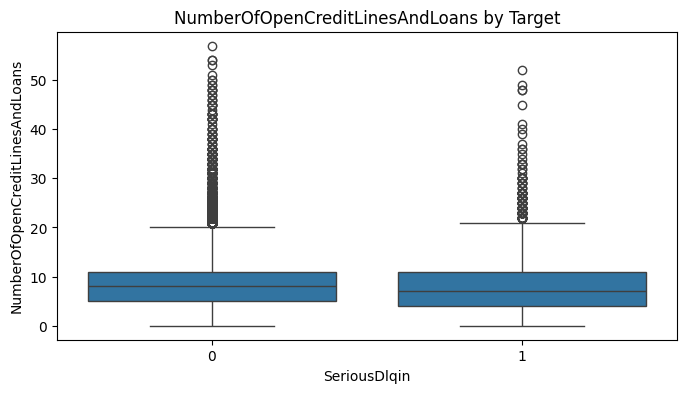

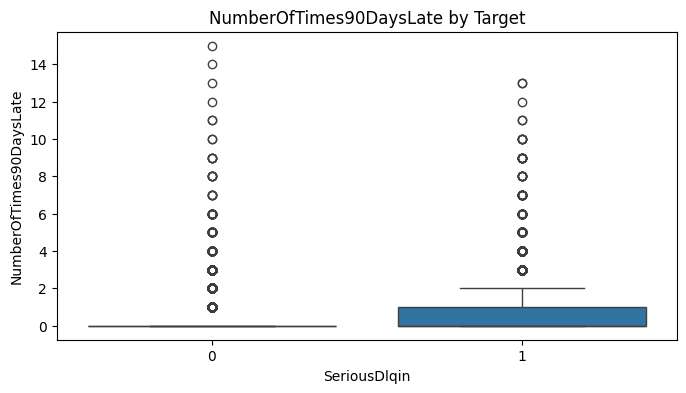

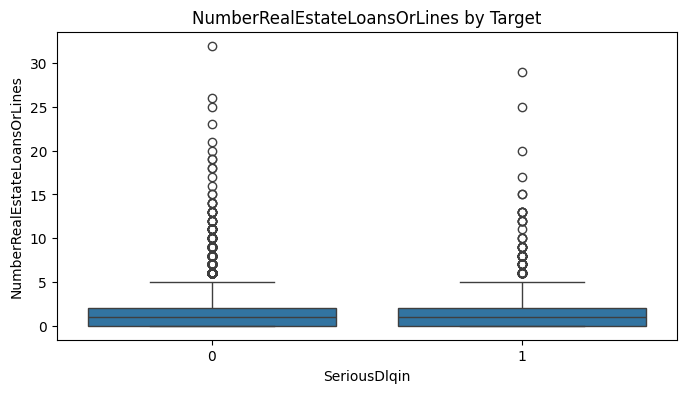

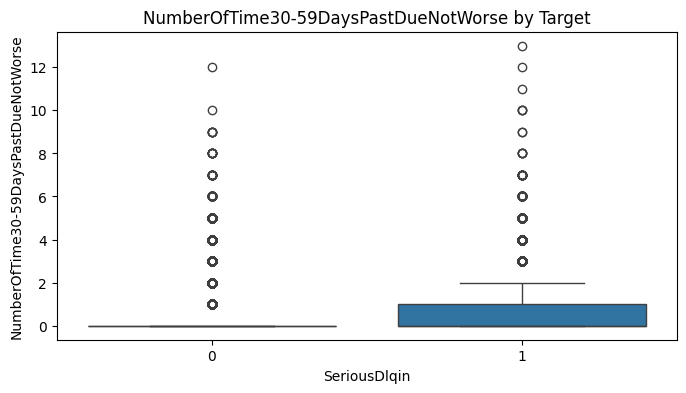

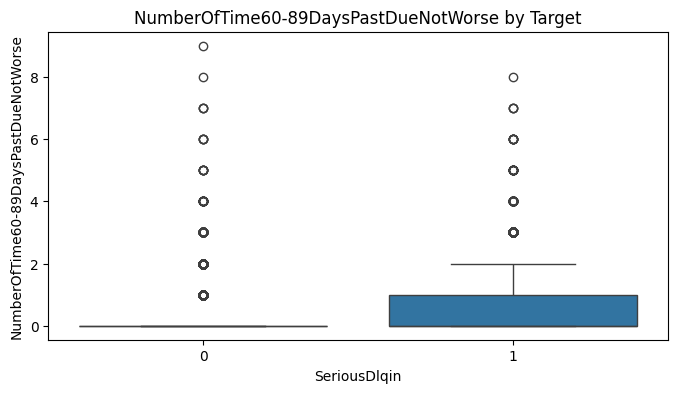

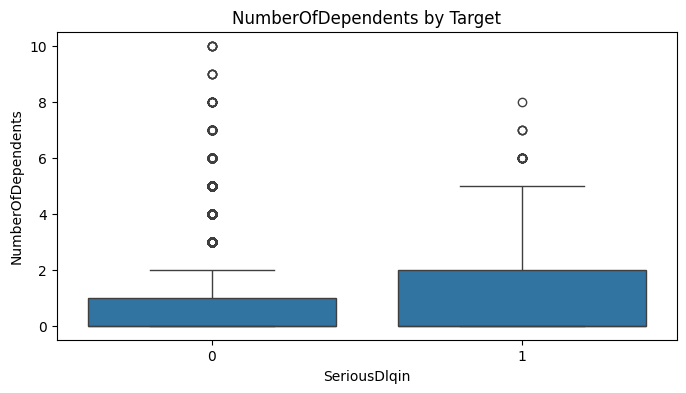

In [33]:
numeric_cols = [
    "age",
    "RevolvingUtilizationOfUnsecuredLines",
    "DebtRatio",
    "MonthlyIncome",
    "NumberOfOpenCreditLinesAndLoans",
    "NumberOfTimes90DaysLate",
    "NumberRealEstateLoansOrLines",
    "NumberOfTime30-59DaysPastDueNotWorse",
    "NumberOfTime60-89DaysPastDueNotWorse",
    "NumberOfDependents"
]

for col in numeric_cols:
    plt.figure(figsize=(8, 4))
    sns.boxplot(data=train_df, x=target, y=col)
    plt.title(f"{col} by Target")
    plt.show()

## 13. Categorical analysis

In [34]:
# Check the new categorical features
print(train_df["SEX"].value_counts().sort_index())
print()
print(train_df["EDUCATION"].value_counts().sort_index())

SEX
0    41808
1    62989
Name: count, dtype: int64

EDUCATION
1    26275
2    36528
3    36724
4     5270
Name: count, dtype: int64


In [35]:
sex_risk = train_df.groupby("SEX")[target].agg(
    Customers="size",
    Bad_Rate="mean"
)
sex_risk["Bad_Rate"] *= 100
sex_risk

,Customers,Bad_Rate
SEX,,
0,41808,6.580080
1,62989,6.610678


In [36]:
education_risk = df.groupby("EDUCATION")[target].agg(
    Customers="size",
    Bad_Rate="mean"
)
education_risk["Bad_Rate"] *= 100
education_risk

,Customers,Bad_Rate
EDUCATION,,
1,37561,6.440191
2,52178,6.713557
3,52482,6.569872
4,7489,6.783282


## 14. Feature Engineering

In [37]:
train_df["TotalPastDue"] = (
    train_df["NumberOfTime30-59DaysPastDueNotWorse"]
    + train_df["NumberOfTime60-89DaysPastDueNotWorse"]
    + train_df["NumberOfTimes90DaysLate"]
)

train_df[[
    "NumberOfTime30-59DaysPastDueNotWorse",
    "NumberOfTime60-89DaysPastDueNotWorse",
    "NumberOfTimes90DaysLate",
    "TotalPastDue"
]].head()

,NumberOfTime30-59DaysPastDueNotWorse,NumberOfTime60-89DaysPastDueNotWorse,NumberOfTimes90DaysLate,TotalPastDue
134668,0,0,0,0
119703,0,0,0,0
37115,0,0,0,0
141624,0,0,0,0
139483,0,0,0,0


In [38]:
test_df["TotalPastDue"] = (
    test_df["NumberOfTime30-59DaysPastDueNotWorse"]
    + test_df["NumberOfTime60-89DaysPastDueNotWorse"]
    + test_df["NumberOfTimes90DaysLate"]
)

test_df[[
    "NumberOfTime30-59DaysPastDueNotWorse",
    "NumberOfTime60-89DaysPastDueNotWorse",
    "NumberOfTimes90DaysLate",
    "TotalPastDue"
]].head()

,NumberOfTime30-59DaysPastDueNotWorse,NumberOfTime60-89DaysPastDueNotWorse,NumberOfTimes90DaysLate,TotalPastDue
76820,0,0,0,0
135401,0,0,0,0
5324,0,1,0,1
90486,0,0,0,0
43461,0,0,0,0


In [39]:
train_df["Has90DaysLate"] = (train_df["NumberOfTimes90DaysLate"] > 0).astype(int)

train_df["Has90DaysLate"].value_counts()

Has90DaysLate
0    99145
1     5652
Name: count, dtype: int64

In [40]:
test_df["Has90DaysLate"] = (test_df["NumberOfTimes90DaysLate"] > 0).astype(int)

test_df["Has90DaysLate"].value_counts()

Has90DaysLate
0    42497
1     2416
Name: count, dtype: int64

In [41]:
pd.crosstab(
    train_df["Has90DaysLate"],
    train_df[target],
    normalize="index"
).round(3)

SeriousDlqin,0,1
Has90DaysLate,,
0,0.954,0.046
1,0.581,0.419


In [42]:
def get_worst_delay_status(row):
    if row["NumberOfTimes90DaysLate"] > 0:
        return 3
    elif row["NumberOfTime60-89DaysPastDueNotWorse"] > 0:
        return 2
    elif row["NumberOfTime30-59DaysPastDueNotWorse"] > 0:
        return 1
    else:
        return 0


train_df["WorstDelayStatus"] = train_df.apply(get_worst_delay_status, axis=1)
test_df["WorstDelayStatus"] = test_df.apply(get_worst_delay_status, axis=1)

## 15. Binning

In [43]:
bins = [0, 29, 39, 49, 59, 69, np.inf]
labels = ["<30", "30-39", "40-49", "50-59", "60-69", "70+"]

train_df["AgeGroup"] = pd.cut(
    train_df["age"],
    bins=bins,
    labels=labels
)

train_df["AgeGroup"].value_counts().sort_index()

AgeGroup
<30       6103
30-39    16157
40-49    23946
50-59    24736
60-69    20305
70+      13550
Name: count, dtype: int64

In [44]:
_, bins = pd.qcut(
    train_df["DebtRatio"],
    q=5,
    retbins=True,
    duplicates="drop"
)

train_df["DebtRatioGroup"] = pd.cut(
    train_df["DebtRatio"],
    bins=bins
)

## 16. WOE and Information Value


In [45]:
woe_table = train_df.groupby(
    "AgeGroup",
    observed=False
)[target].agg(
    Total="size",
    Bad="sum"
)

woe_table["Good"] = woe_table["Total"] - woe_table["Bad"]

woe_table

,Total,Bad,Good
AgeGroup,,,
<30,6103,682,5421
30-39,16157,1610,14547
40-49,23946,1992,21954
50-59,24736,1592,23144
60-69,20305,723,19582
70+,13550,316,13234


In [46]:
woe_table["Bad_Dist"] = (
    woe_table["Bad"] / woe_table["Bad"].sum()
)

woe_table["Good_Dist"] = (
    woe_table["Good"] / woe_table["Good"].sum()
)

In [47]:
woe_table["WOE"] = np.log(
    woe_table["Good_Dist"] /
    woe_table["Bad_Dist"]
)

woe_table["IV"] = (
    woe_table["Good_Dist"] -
    woe_table["Bad_Dist"]
) * woe_table["WOE"]

In [48]:
IV = woe_table["IV"].sum()

print("IV =", IV)

IV = 0.2379444781393713


In [49]:
train_df.drop(
    columns=["AgeGroup", "DebtRatioGroup"],
    inplace=True
)

## 17. Feature Redundancy

In [50]:
numeric_columns = [
    "age",
    "RevolvingUtilizationOfUnsecuredLines",
    "DebtRatio",
    "MonthlyIncome",
    "NumberOfOpenCreditLinesAndLoans",
    "NumberOfTimes90DaysLate",
    "NumberRealEstateLoansOrLines",
    "NumberOfTime30-59DaysPastDueNotWorse",
    "NumberOfTime60-89DaysPastDueNotWorse",
    "NumberOfDependents",

    # New Features
    "TotalPastDue",
    "Has90DaysLate",
    "WorstDelayStatus",
    "MonthlyIncome_missing"
]

X = train_df[numeric_columns].copy()

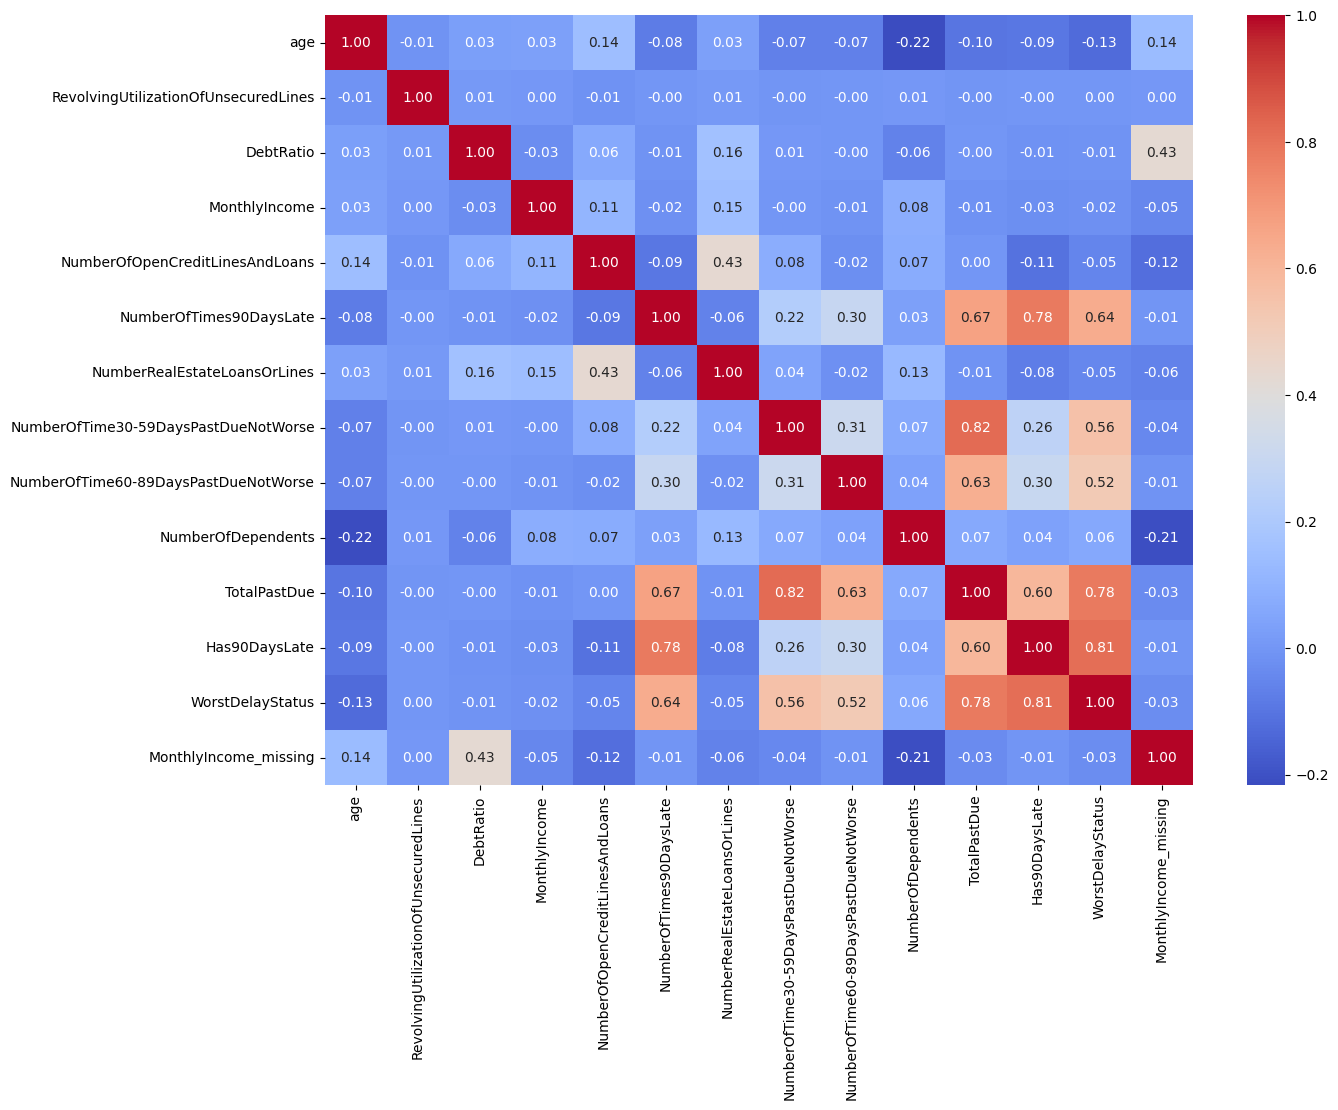

In [51]:
corr_matrix = X.corr()

plt.figure(figsize=(14, 10))

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.show()

## 18. Mutual information

TotalPastDue                            0.048711
WorstDelayStatus                        0.047974
RevolvingUtilizationOfUnsecuredLines    0.036869
NumberOfTimes90DaysLate                 0.032128
Has90DaysLate                           0.031938
NumberOfTime30-59DaysPastDueNotWorse    0.026587
NumberOfTime60-89DaysPastDueNotWorse    0.019390
SEX                                     0.017107
age                                     0.007307
EDUCATION                               0.006537
NumberRealEstateLoansOrLines            0.006051
NumberOfOpenCreditLinesAndLoans         0.005024
MonthlyIncome                           0.005007
DebtRatio                               0.004014
MonthlyIncome_missing                   0.002231
NumberOfDependents                      0.001624
dtype: float64


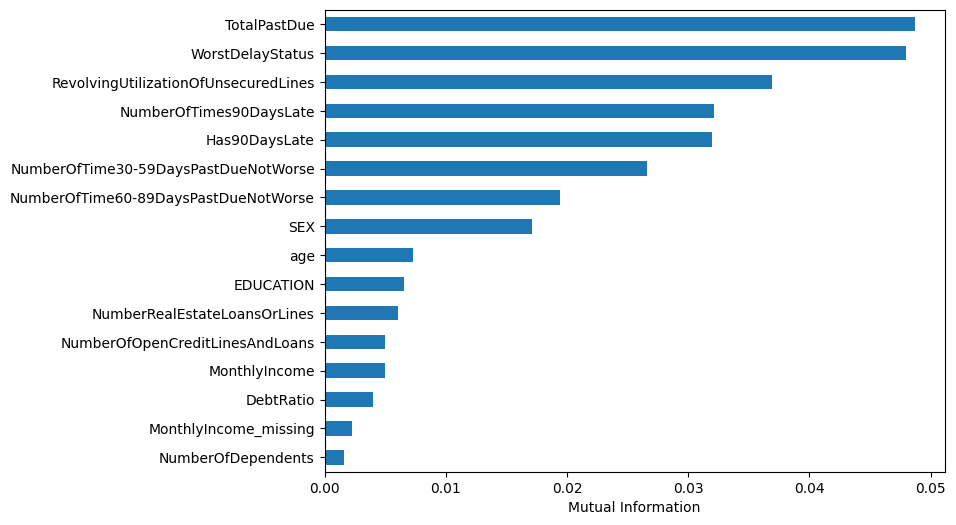

In [52]:
X = train_df.drop(columns=[target, "Is_Outlier"])
y = train_df[target]

mi = mutual_info_classif(X, y, random_state=42)

mi_scores = pd.Series(mi, index=X.columns).sort_values(ascending=False)

print(mi_scores)

mi_scores.sort_values().plot.barh(figsize=(8, 6))
plt.xlabel("Mutual Information")
plt.show()

## 19. Train data summary

In [53]:
train_numeric_report = train_df.select_dtypes(include=np.number).describe().T

train_numeric_report

,count,mean,std,min,25%,50%,75%,max
RevolvingUtilizationOfUnsecuredLines,104797.0,6.173620,216.960110,0.0,0.029924,0.153382,0.555344,22198.0
age,104797.0,52.341508,14.739044,21.0,41.000000,52.000000,63.000000,99.0
SEX,104797.0,0.601057,0.489683,0.0,0.000000,1.000000,1.000000,1.0
EDUCATION,104797.0,2.200282,0.873039,1.0,1.000000,2.000000,3.000000,4.0
NumberOfTime30-59DaysPastDueNotWorse,104797.0,0.244702,0.695424,0.0,0.000000,0.000000,0.000000,13.0
DebtRatio,104797.0,349.161128,1515.546006,0.0,0.175977,0.366682,0.864820,220516.0
MonthlyIncome,104797.0,6394.189004,10178.917654,0.0,3923.000000,5416.000000,7420.000000,1794060.0
NumberOfOpenCreditLinesAndLoans,104797.0,8.465777,5.129409,0.0,5.000000,8.000000,11.000000,57.0
NumberOfTimes90DaysLate,104797.0,0.090814,0.485827,0.0,0.000000,0.000000,0.000000,15.0
NumberRealEstateLoansOrLines,104797.0,1.019380,1.120560,0.0,0.000000,1.000000,2.000000,32.0


In [54]:
new_features = [
    "WorstDelayStatus",
    "TotalPastDue",
    "Has90DaysLate",
]

train_df[new_features].head()

,WorstDelayStatus,TotalPastDue,Has90DaysLate
134668,0,0,0
119703,0,0,0
37115,0,0,0
141624,0,0,0
139483,0,0,0


In [55]:
new_features = [
    "WorstDelayStatus",
    "TotalPastDue",
    "Has90DaysLate",
]

train_df.groupby(target)[new_features].mean().T

SeriousDlqin,0,1
WorstDelayStatus,0.258618,1.487346
TotalPastDue,0.283852,2.051916
Has90DaysLate,0.033540,0.342589


## 20. Test data summary


In [56]:
test_numeric_report = test_df.select_dtypes(include=np.number).describe().T

test_numeric_report

,count,mean,std,min,25%,50%,75%,max
RevolvingUtilizationOfUnsecuredLines,44913.0,4.660321,203.115815,0.0,0.029542,0.153936,0.556688,29110.0
age,44913.0,52.281077,14.767130,21.0,41.000000,52.000000,63.000000,99.0
SEX,44913.0,0.602031,0.489485,0.0,0.000000,1.000000,1.000000,1.0
EDUCATION,44913.0,2.198384,0.872026,1.0,1.000000,2.000000,3.000000,4.0
NumberOfTime30-59DaysPastDueNotWorse,44913.0,0.248347,0.703317,0.0,0.000000,0.000000,0.000000,9.0
DebtRatio,44913.0,342.658266,1277.865620,0.0,0.176137,0.368217,0.883749,110952.0
MonthlyIncome,44913.0,6434.311313,10600.336519,0.0,3900.000000,5416.000000,7300.000000,1072500.0
NumberOfOpenCreditLinesAndLoans,44913.0,8.472224,5.153499,0.0,5.000000,8.000000,11.000000,57.0
NumberOfTimes90DaysLate,44913.0,0.089618,0.484859,0.0,0.000000,0.000000,0.000000,17.0
NumberRealEstateLoansOrLines,44913.0,1.020551,1.124151,0.0,0.000000,1.000000,2.000000,25.0


In [57]:
new_features = [
    "WorstDelayStatus",
    "TotalPastDue",
    "Has90DaysLate",
]

test_df[new_features].head()

,WorstDelayStatus,TotalPastDue,Has90DaysLate
76820,0,0,0
135401,0,0,0
5324,2,1,0
90486,0,0,0
43461,0,0,0


In [58]:
summary_features = [
    "WorstDelayStatus",
    "TotalPastDue",
    "Has90DaysLate"
]

test_df.groupby(target)[summary_features].mean().T

SeriousDlqin,0,1
WorstDelayStatus,0.267747,1.419507
TotalPastDue,0.291180,1.977050
Has90DaysLate,0.034803,0.322646


## 21. Part A: Export the prepared `train.csv` and `test.csv`

1. **Why is `index=False` important?** If the index is saved, a column named `Unnamed: 0` is introduced into the file. When re-imported, this is incorrectly treated as a "feature" (and since the training indices are shuffled after the split, it carries meaningless—yet learnable—information regarding the original row order). The trade-off: rows can no longer be traced back to their original identifiers; if such traceability is required, a separate ID column must be saved.
2. **The auxiliary column `Is_Outlier`:** This column exists only in `train_df` and not in `test_df`. It serves as an "analytical flag" rather than a feature. If it were exported, the training and test datasets would no longer be consistent, and the model might mistakenly interpret it as a feature. Therefore, it is removed prior to export (and can be reconstructed from the raw data in Section C, if needed).
3. **What does "prepared" entail?** Outlier removal and balancing (Section C) are modeling experiments performed exclusively on the training set. Consequently, we export the files *before* these steps—ensuring the test set remains untouched and the training set consists solely of authentic (non-synthetic) data.

In [ ]:
train_export = train_df.drop(columns=["Is_Outlier"], errors="ignore")
test_export = test_df[train_export.columns]          # same columns, same order

assert list(train_export.columns) == list(test_export.columns)
assert train_export.isna().sum().sum() == 0, "train still has missing values"
assert test_export.isna().sum().sum() == 0, "test still has missing values"

train_export.to_csv("train.csv", index=False)
test_export.to_csv("test.csv", index=False)

train = pd.read_csv("train.csv")
test = pd.read_csv("test.csv")
assert not any(c.startswith("Unnamed") for c in train.columns), "the index was saved by mistake"

print("train.csv:", train.shape, "| test.csv:", test.shape)
print("Columns  :", list(train.columns))
print(f"Delinquency rate -> train: {train[target].mean():.2%} | test: {test[target].mean():.2%}")

train.csv: (104797, 17) | test.csv: (44913, 17)
Columns  : ['RevolvingUtilizationOfUnsecuredLines', 'age', 'SEX', 'EDUCATION', 'NumberOfTime30-59DaysPastDueNotWorse', 'DebtRatio', 'MonthlyIncome', 'NumberOfOpenCreditLinesAndLoans', 'NumberOfTimes90DaysLate', 'NumberRealEstateLoansOrLines', 'NumberOfTime60-89DaysPastDueNotWorse', 'NumberOfDependents', 'SeriousDlqin', 'MonthlyIncome_missing', 'TotalPastDue', 'Has90DaysLate', 'WorstDelayStatus']
Delinquency rate -> train: 6.60% | test: 6.60%


## 22. Part B: Does the Random Forest really detect delinquency?

1. **Which is the positive class?** `SeriousDlqin = 1` (a "bad" or delinquent customer), which accounts for only about 6.6% of the data. Precision, recall, and the F1-score should be reported **specifically for this class**; using `macro` or `weighted` averages—or overall accuracy—would be skewed by the majority class, effectively masking the model's weaknesses.
2. **Support** refers to the *actual* number of samples for each class in the test set (not the number of predictions).
3. **Confusion Matrix:** Rows represent the actual classes, while columns represent the predicted classes. By setting `labels=[0, 1]`, we fix the order so that the cells correspond to `TN, FP / FN, TP`.
4. **Baseline:** To evaluate accuracy, it should be compared against a trivial (useless) model that always predicts the "good" (non-delinquent) class.

In [ ]:
RANDOM_STATE = 42

X_train, y_train = train.drop(columns=[target]), train[target]
X_test, y_test = test.drop(columns=[target]), test[target]

rf_base = RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1)
rf_base.fit(X_train, y_train)

y_pred = rf_base.predict(X_test)
y_proba = rf_base.predict_proba(X_test)[:, 1]

In [ ]:
class_names = ["No delinquency (0)", "Delinquency (1)"]

print("Overall accuracy:", round(accuracy_score(y_test, y_pred), 4))
print()
print(classification_report(y_test, y_pred, target_names=class_names, digits=3))

prec, rec, f1, sup = precision_recall_fscore_support(y_test, y_pred, labels=[1], zero_division=0)
metrics_B = pd.DataFrame({"Precision": prec, "Recall": rec, "F1-score": f1, "Support": sup},
                         index=["Delinquency (SeriousDlqin = 1)"])
display(metrics_B.round(4))

Overall accuracy: 0.9363

                    precision    recall  f1-score   support

No delinquency (0)      0.945     0.989     0.967     41950
   Delinquency (1)      0.550     0.188     0.280      2963

          accuracy                          0.936     44913
         macro avg      0.748     0.589     0.623     44913
      weighted avg      0.919     0.936     0.921     44913



,Precision,Recall,F1-score,Support
Delinquency (SeriousDlqin = 1),0.5504,0.188,0.2803,2963


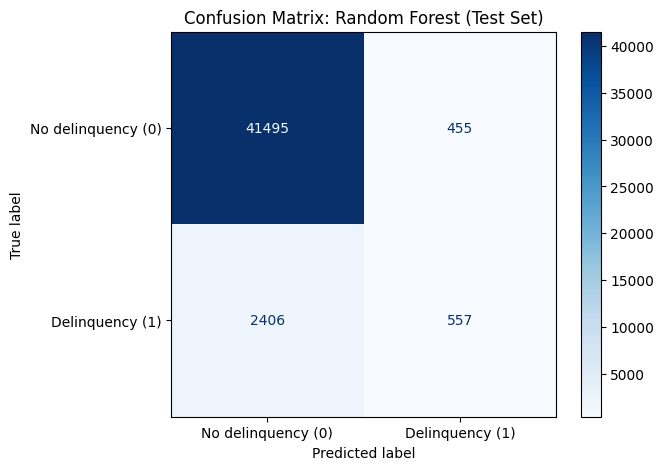

True Negatives  (good customers predicted good)      : 41495
False Positives (good customers flagged as risky)     : 455
False Negatives (delinquent customers MISSED)         : 2406
True Positives  (delinquent customers detected)       : 557

Share of delinquent customers missed: 81.2%


In [62]:
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
fig, ax = plt.subplots(figsize=(6.5, 5))
ConfusionMatrixDisplay(cm, display_labels=class_names).plot(ax=ax, cmap="Blues", values_format="d")
ax.set_xlabel("Predicted label")
ax.set_ylabel("True label")
ax.set_title("Confusion Matrix: Random Forest (Test Set)")
plt.show()

tn, fp, fn, tp = cm.ravel()
print(f"True Negatives  (good customers predicted good)      : {tn}")
print(f"False Positives (good customers flagged as risky)     : {fp}")
print(f"False Negatives (delinquent customers MISSED)         : {fn}")
print(f"True Positives  (delinquent customers detected)       : {tp}")
print(f"\nShare of delinquent customers missed: {fn / (fn + tp):.1%}")

In [ ]:
dummy = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
y_dummy = dummy.predict(X_test)

comparison = pd.DataFrame({
    "Model": ["Always predict 'No delinquency'", "Random Forest (baseline)"],
    "Accuracy": [accuracy_score(y_test, y_dummy), accuracy_score(y_test, y_pred)],
    "Recall (class 1)": [recall_score(y_test, y_dummy, zero_division=0), recall_score(y_test, y_pred)],
    "F1 (class 1)": [f1_score(y_test, y_dummy, zero_division=0), f1_score(y_test, y_pred)],
}).set_index("Model")
display(comparison.round(4))

print("ROC-AUC          :", round(roc_auc_score(y_test, y_proba), 4))
print("Average precision:", round(average_precision_score(y_test, y_proba), 4),
      f"(a random model would score about {y_test.mean():.3f})")

,Accuracy,Recall (class 1),F1 (class 1)
Model,,,
Always predict 'No delinquency',0.9340,0.000,0.0000
Random Forest (baseline),0.9363,0.188,0.2803


ROC-AUC          : 0.8306
Average precision: 0.3474 (a random model would score about 0.066)


**Answer: Why is accuracy alone misleading?**

In this dataset, only about 6.6% of customers are "bad" (defaulting/delinquent). A useless model that **always** predicts "not bad" would achieve an accuracy of **0.9340**—without identifying a single bad customer. A baseline Random Forest model has an accuracy of **0.9363**, which is only about **0.2%** better than this useless model. However, the metrics for the "bad" class reveal what is actually happening:

- **Recall is approximately 0.188:** Out of 2,963 truly bad customers, only 557 were identified, while 2,406 (about **81%**) were missed (False Negatives).
- **Precision is approximately 0.550:** For every 100 alerts generated by the model, about 55 are correct.
- **F1-score is approximately 0.280:** The harmonic mean of these two metrics, which is significantly lower than the accuracy.

In a real-world application (such as loan underwriting), the cost of missing a bad customer is far greater than the cost of performing an additional review on a good customer; therefore, the recall for the "bad" class is a more critical metric. **Conclusion:** At first glance, the Random Forest model appears excellent with an accuracy of around 94%, but in practice, it fails to detect approximately 81% of bad customers. Thus, "high accuracy" does not equate to "effective detection of bad customers."

## 23. Part C: Improve the model (balancing, outliers, model choice, tuning)

1. **Internal Contradiction in the Exercise:** Part B states that accuracy is misleading, yet Part C instructs to "increase accuracy." With a baseline of 93.4%, the potential for improving accuracy is limited to just a few hundredths of a percent. Furthermore, **balancing typically reduces accuracy**—as the model flags more customers as "bad" (delinquent), including some who are actually "good"—while simultaneously increasing recall. Thus, the objective of "balancing to increase accuracy" is inherently contradictory. While we will report accuracy (as requested), we will identify the best model based on *both* accuracy and the F1-score for Class 1.
2. **Removing Outliers via the IQR Rule Can Be Disastrous:** In count-based columns (such as `NumberOfTimes90DaysLate`), both the first and third quartiles are zero; consequently, the IQR is 0, meaning **any non-zero value is classified as an "outlier."** The rule applied in cell 38 of the notebook flags approximately **48.9% of the training rows**—and about **78% of all "bad" (delinquent) cases**—as outliers. Yet, these are precisely the most critical instances. A more logical approach would be to remove outliers only from **continuous** variables (e.g., `RevolvingUtilizationOfUnsecuredLines`, `DebtRatio`, `MonthlyIncome`) using a threshold such as 3×IQR. Moreover, outliers should be removed exclusively from the **training set**, leaving the test set untouched (as outliers naturally exist in real-world data).
3. **Data Leakage During Balancing:** SMOTENC must be applied solely to the training set (or, in the context of cross-validation, only to the training fold)—never to the test set or prior to the data split. Otherwise, synthetic samples generated from test-set rows would inadvertently leak into the training process. For this reason, we utilize `imblearn.pipeline.Pipeline`. 4. **SMOTENC and Derived Features:** SMOTENC interpolates the values ​​of count-based columns (e.g., "number of 90-day late payments"). Consequently, the derived columns—such as `TotalPastDue`, `Has90DaysLate`, and `WorstDelayStatus`—become inconsistent with these interpolated values. Since count-based features are always integers in real-world data, the model might learn to use the presence of "non-integer" (decimal) values ​​as a shortcut to identify synthetic samples. To address this, after applying SMOTENC, we round the count-based features and recompute the derived columns. Table C.1 compares both versions (raw and corrected); **while this adjustment ensures consistency, it does not necessarily improve the final results.**
5. **Selecting the "Best" Model via the Test Set Leads to Data Leakage:** If multiple models are compared using the test set to select the best one, the reported accuracy will be overly optimistic. Therefore, model selection must be performed exclusively through **cross-validation on the training set**, while the test set should be used **only once**—specifically for the final models.

### C.0 helper functions

In [ ]:
CONTINUOUS_COLS = ["RevolvingUtilizationOfUnsecuredLines", "DebtRatio", "MonthlyIncome"]
ALL_NUMERIC_COLS = ["age", "RevolvingUtilizationOfUnsecuredLines", "DebtRatio", "MonthlyIncome",
                    "NumberOfOpenCreditLinesAndLoans", "NumberOfTimes90DaysLate",
                    "NumberRealEstateLoansOrLines", "NumberOfTime30-59DaysPastDueNotWorse",
                    "NumberOfTime60-89DaysPastDueNotWorse", "NumberOfDependents"]
CATEGORICAL_COLS = ["SEX", "EDUCATION", "MonthlyIncome_missing", "Has90DaysLate", "WorstDelayStatus"]
CATEGORICAL_IDX = [X_train.columns.get_loc(c) for c in CATEGORICAL_COLS]
INTEGER_COLS = ["age", "NumberOfTime30-59DaysPastDueNotWorse", "NumberOfTime60-89DaysPastDueNotWorse",
                "NumberOfTimes90DaysLate", "NumberOfOpenCreditLinesAndLoans",
                "NumberRealEstateLoansOrLines", "NumberOfDependents"]



def drop_outliers(X, y, cols=CONTINUOUS_COLS, k=3.0):
    X = pd.DataFrame(X)
    keep = np.ones(len(X), dtype=bool)
    for c in cols:
        q1, q3 = X[c].quantile([0.25, 0.75])
        iqr = q3 - q1
        keep &= ((X[c] >= q1 - k * iqr) & (X[c] <= q3 + k * iqr)).to_numpy()
    return X[keep], np.asarray(y)[keep]



def rebuild_derived(X, y):
    X = pd.DataFrame(X).copy()
    for c in INTEGER_COLS:                      # counts / age must be whole numbers
        X[c] = X[c].round()
    late30 = X["NumberOfTime30-59DaysPastDueNotWorse"]
    late60 = X["NumberOfTime60-89DaysPastDueNotWorse"]
    late90 = X["NumberOfTimes90DaysLate"]
    X["TotalPastDue"] = late30 + late60 + late90
    X["Has90DaysLate"] = (late90 > 0).astype(int)
    X["WorstDelayStatus"] = np.select([late90 > 0, late60 > 0, late30 > 0], [3, 2, 1], default=0)
    return X, y


def sampler_steps(sampler):
    if sampler == "outliers":          
        return [("outliers", FunctionSampler(func=drop_outliers, validate=False))]
    if sampler == "outliers_all":      
        return [("outliers", FunctionSampler(func=drop_outliers, validate=False,
                                             kw_args={"cols": ALL_NUMERIC_COLS, "k": 1.5}))]
    if sampler == "smotenc_raw":       
        return [("smotenc", SMOTENC(categorical_features=CATEGORICAL_IDX, random_state=RANDOM_STATE))]
    if sampler == "smotenc":           
        return [("smotenc", SMOTENC(categorical_features=CATEGORICAL_IDX, random_state=RANDOM_STATE)),
                ("rebuild", FunctionSampler(func=rebuild_derived, validate=False))]
    return []


def resample_train(sampler):
    """Apply a training-set-only treatment to the full train data."""
    Xr, yr = X_train, y_train
    for _, step in sampler_steps(sampler):
        Xr, yr = step.fit_resample(Xr, yr)
    return Xr, pd.Series(yr)


def build(model, sampler="none", **params):
    """imblearn Pipeline: [train-only sampler steps] -> classifier."""
    steps = sampler_steps(sampler)
    if model == "rf":
        steps.append(("clf", RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1, **params)))
    elif model == "hgb":
        steps.append(("clf", HistGradientBoostingClassifier(random_state=RANDOM_STATE, **params)))
    elif model == "lr":
        steps.append(("scale", StandardScaler()))
        steps.append(("clf", LogisticRegression(max_iter=1000, **params)))
    return Pipeline(steps)


def score_on_test(fitted):
    pred = fitted.predict(X_test)
    proba = fitted.predict_proba(X_test)[:, 1]
    p, r, f, _ = precision_recall_fscore_support(y_test, pred, labels=[1], zero_division=0)
    return {"Accuracy": accuracy_score(y_test, pred), "Precision (1)": p[0], "Recall (1)": r[0],
            "F1 (1)": f[0], "ROC-AUC": roc_auc_score(y_test, proba)}, pred

print("scikit-learn", sklearn.__version__, "| imbalanced-learn", imblearn.__version__,
      "(class_weight in HistGradientBoostingClassifier needs scikit-learn >= 1.2)")
print("Helpers ready. Delinquent share in train:", f"{y_train.mean():.2%}")

scikit-learn 1.9.1 | imbalanced-learn 0.14.2 (class_weight in HistGradientBoostingClassifier needs scikit-learn >= 1.2)
Helpers ready. Delinquent share in train: 6.60%


### C.1 Effect of each technique on its own (Random Forest, 100 trees; descriptive results on the test set)

In [65]:
experiments = [
    ("Baseline (no treatment)",                              "none",         {}),
    ("Class weights (balanced_subsample)",                   "none",         {"class_weight": "balanced_subsample"}),
    ("SMOTENC (raw interpolation)",                          "smotenc_raw",  {}),
    ("SMOTENC + rounding + rebuilt derived features",        "smotenc",      {}),
    ("Outliers removed: IQR 1.5 on ALL 10 numeric columns",  "outliers_all", {}),
    ("Outliers removed: IQR 3 on 3 continuous columns",      "outliers",     {}),
]

rows = []
for name, sampler, params in experiments:
    Xr, yr = resample_train(sampler)
    model = RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1, **params).fit(Xr, yr)
    scores, _ = score_on_test(model)
    rows.append({"Strategy": name, "Train rows": len(yr), "Delinquent in train": int(yr.sum()), **scores})

ablation = pd.DataFrame(rows).set_index("Strategy")
display(ablation.round(4))

,Train rows,Delinquent in train,Accuracy,Precision (1),Recall (1),F1 (1),ROC-AUC
Strategy,,,,,,,
Baseline (no treatment),104797,6915,0.9363,0.5504,0.1880,0.2803,0.8306
Class weights (balanced_subsample),104797,6915,0.9357,0.5475,0.1478,0.2328,0.8312
SMOTENC (raw interpolation),195764,97882,0.9234,0.4030,0.3351,0.3659,0.8254
SMOTENC + rounding + rebuilt derived features,195764,97882,0.8245,0.2060,0.5818,0.3043,0.8067
Outliers removed: IQR 1.5 on ALL 10 numeric columns,53590,1491,0.9338,0.3226,0.0034,0.0067,0.7058
Outliers removed: IQR 3 on 3 continuous columns,81190,5585,0.9354,0.5295,0.1910,0.2808,0.8185


**Interpretation C.1:**

- **Baseline:** Accuracy ~0.936, recall ~0.19, F1 ~0.28, ROC-AUC ~0.83.
- **Class weight (with fully grown trees):** Has almost no effect (recall ~0.15, accuracy ~0.936). Reason: With `min_samples_leaf=1`, the leaf nodes are pure, rendering class weights largely inconsequential. The impact of class weights depends on the size of the leaf nodes; in C.2, with `min_samples_leaf=5`, this effect becomes apparent (recall ~0.18 vs. ~0.48).
- **Raw SMOTENC:** Recall reaches ~0.33, but precision drops to ~0.40 and accuracy to ~0.922; the ROC-AUC (~0.825) shows no improvement over the baseline.
- **SMOTENC with rounding and feature reconstruction:** The model becomes more "aggressive" (recall ~0.58, precision ~0.21, accuracy ~0.82). Removing the "decimal-value" shortcut significantly alters the model's behavior; however, the F1 score (~0.30) and ROC-AUC (~0.81) do not improve.
- **Outlier removal based on all columns (affecting ~48% of rows and ~78% of "bad" accounts):** Recall plummets to ~**0.003** and ROC-AUC drops to ~0.70, yet the accuracy (~0.933) still appears "good." This serves as a vivid example of how misleading accuracy can be. - **Removing outliers only from continuous columns:** The change is negligible (trees are robust to outliers).

### C.2 Model selection and hyperparameter tuning with 3-fold cross-validation (train set only)

In [ ]:
configs = []

for cw, leaf in itertools.product([None, "balanced_subsample"], [1, 5]):
    configs.append(("rf", "none", {"min_samples_leaf": leaf, "class_weight": cw}))
configs.append(("rf", "smotenc_raw", {"min_samples_leaf": 5}))
configs.append(("rf", "smotenc", {"min_samples_leaf": 5}))
l
for lr, leaves, cw in itertools.product([0.05, 0.1], [15, 31], [None, "balanced"]):
    configs.append(("hgb", "none", {"learning_rate": lr, "max_leaf_nodes": leaves, "class_weight": cw}))
configs.append(("hgb", "smotenc_raw", {"learning_rate": 0.1, "max_leaf_nodes": 31}))
configs.append(("hgb", "smotenc", {"learning_rate": 0.1, "max_leaf_nodes": 31}))
configs.append(("hgb", "outliers", {"learning_rate": 0.1, "max_leaf_nodes": 31}))

configs.append(("lr", "none", {"C": 1.0}))
configs.append(("lr", "none", {"C": 1.0, "class_weight": "balanced"}))

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
cv_rows = []
start = time.time()
for model_name, sampler, params in configs:
    res = cross_validate(build(model_name, sampler, **params), X_train, y_train, cv=cv,
                         scoring=["accuracy", "precision", "recall", "f1", "roc_auc"])
    cv_rows.append({"model": model_name, "sampler": sampler, "params": params,
                    "cv_accuracy": res["test_accuracy"].mean(), "cv_precision": res["test_precision"].mean(),
                    "cv_recall": res["test_recall"].mean(), "cv_f1": res["test_f1"].mean(),
                    "cv_roc_auc": res["test_roc_auc"].mean()})
print(f"Cross-validation finished in {time.time() - start:.0f} seconds for {len(configs)} configurations.")

cv_results = pd.DataFrame(cv_rows)
display(cv_results.sort_values("cv_f1", ascending=False).assign(params=lambda d: d["params"].astype(str))
        .round(4).reset_index(drop=True))

Cross-validation finished in 499 seconds for 19 configurations.


,model,sampler,params,cv_accuracy,cv_precision,cv_recall,cv_f1,cv_roc_auc
0,rf,none,"{'min_samples_leaf': 5, 'class_weight': 'balanced_subsample'}",0.9148,0.3850,0.4872,0.4301,0.8562
1,rf,smotenc_raw,{'min_samples_leaf': 5},0.9215,0.4023,0.3910,0.3966,0.8479
2,hgb,smotenc_raw,"{'learning_rate': 0.1, 'max_leaf_nodes': 31}",0.9219,0.4024,0.3796,0.3906,0.8467
3,lr,none,"{'C': 1.0, 'class_weight': 'balanced'}",0.8383,0.2382,0.6600,0.3501,0.8251
4,hgb,none,"{'learning_rate': 0.1, 'max_leaf_nodes': 31, 'class_weight': 'balanced'}",0.8061,0.2206,0.7649,0.3424,0.8646
5,hgb,none,"{'learning_rate': 0.05, 'max_leaf_nodes': 31, 'class_weight': 'balanced'}",0.8047,0.2195,0.7667,0.3412,0.8650
6,hgb,none,"{'learning_rate': 0.1, 'max_leaf_nodes': 15, 'class_weight': 'balanced'}",0.7991,0.2158,0.7761,0.3377,0.8660
7,hgb,none,"{'learning_rate': 0.05, 'max_leaf_nodes': 15, 'class_weight': 'balanced'}",0.7963,0.2138,0.7798,0.3356,0.8661
8,rf,smotenc,{'min_samples_leaf': 5},0.8123,0.2100,0.6678,0.3195,0.8304
9,hgb,smotenc,"{'learning_rate': 0.1, 'max_leaf_nodes': 31}",0.7836,0.1903,0.6999,0.2992,0.8236


### C.3 Final evaluation: best model by accuracy vs best model by F1 (test set used once)

,Model,Balancing / outliers,Hyperparameters,Accuracy,Precision (1),Recall (1),F1 (1),ROC-AUC
Selection,,,,,,,,
Best by CV accuracy (what the exercise literally asks),hgb,none,"{'learning_rate': 0.05, 'max_leaf_nodes': 15, 'class_weight': None}",0.9381,0.6096,0.1708,0.2668,0.8553
Best by CV F1 of class 1 (recommended criterion),rf,none,"{'min_samples_leaf': 5, 'class_weight': 'balanced_subsample'}",0.9127,0.3739,0.4803,0.4204,0.8474


Reference -> always 'No delinquency': accuracy = 0.9340 | baseline Random Forest: accuracy = 0.9363, recall(1) = 0.1880


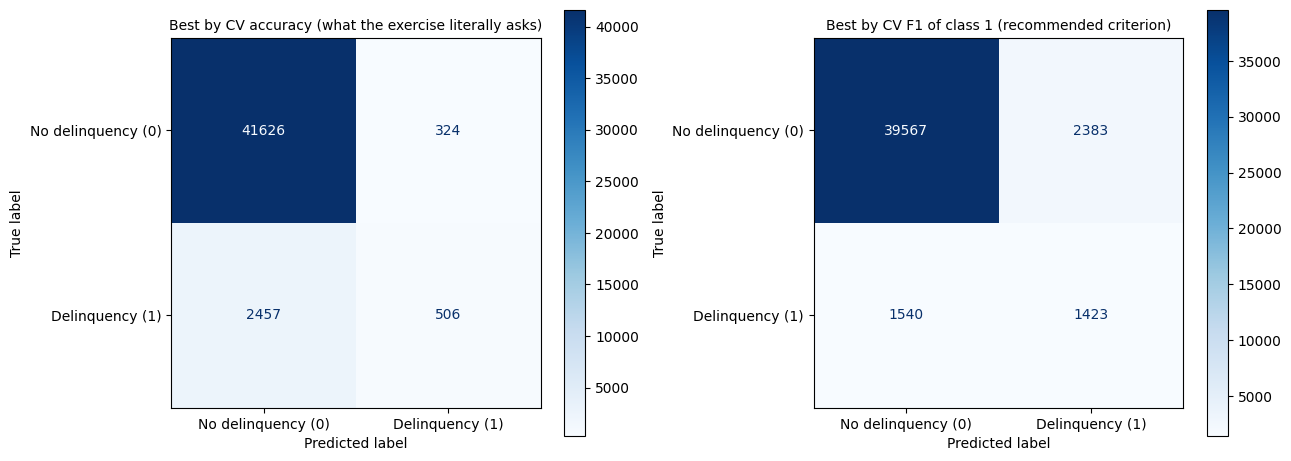

In [ ]:
finalists = [("Best by CV accuracy (what the exercise literally asks)", "cv_accuracy"),
             ("Best by CV F1 of class 1 (recommended criterion)", "cv_f1")]

final_rows, final_preds = [], {}
for label, criterion in finalists:
    best = cv_results.sort_values(criterion, ascending=False).iloc[0]
    fitted = build(best["model"], best["sampler"], **best["params"]).fit(X_train, y_train)
    scores, pred = score_on_test(fitted)
    final_preds[label] = pred
    final_rows.append({"Selection": label, "Model": best["model"], "Balancing / outliers": best["sampler"],
                       "Hyperparameters": str(best["params"]), **scores})

final_table = pd.DataFrame(final_rows).set_index("Selection")
display(final_table.round(4))

print(f"Reference -> always 'No delinquency': accuracy = {accuracy_score(y_test, y_dummy):.4f} "
      f"| baseline Random Forest: accuracy = {accuracy_score(y_test, y_pred):.4f}, "
      f"recall(1) = {recall_score(y_test, y_pred):.4f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, (label, _) in zip(axes, finalists):
    ConfusionMatrixDisplay.from_predictions(y_test, final_preds[label], labels=[0, 1],
                                            display_labels=class_names, ax=ax,
                                            cmap="Blues", values_format="d")
    ax.set_title(label, fontsize=10)
    ax.set_xlabel("Predicted label")
    ax.set_ylabel("True label")
plt.tight_layout()
plt.show()

## Final Answer for Part C: Best Model, Hyperparameters, and Accuracy

(The values ​​are derived from our run with `random_state=42`; Table C.3 displays the exact results of this specific run.)

| Selection Criterion (via cross-validation on the training set) | Best Model and Hyperparameters | Accuracy (test) | Recall (Class 1) | F1 (Class 1) |
|:---|:---|:---:|:---:|:---:|
| **Highest Accuracy** (as literally requested by the exercise) | `HistGradientBoostingClassifier` with `learning_rate=0.05`, `max_leaf_nodes=31`, no class weighting, and no balancing | **~0.938** | ~0.17 | ~0.27 |
| **Highest F1 (Class 1)** (suggested criterion) | `RandomForestClassifier` with `n_estimators=100`, `min_samples_leaf=5`, `class_weight='balanced_subsample'` | ~0.913 | ~0.48 | ~0.42 |

**Summary and Analysis:**

1. **Improving accuracy is virtually impossible—and pointless:** The best accuracy (~0.938) is only about 0.4% higher than that of the useless "always predict 'healthy'" model (0.934) and about 0.2% higher than a baseline Random Forest (0.936). Furthermore, the recall remains at approximately 17%, meaning that about 83% of the "bad" cases (defaults) go undetected.

2. **Balancing and accuracy are in conflict:** The model optimized for the F1-score—achieved via class weighting—reduces accuracy by approximately 2.5% but increases recall more than **two-and-a-half-fold** (from about 0.17 to roughly 0.48). Despite having "lower accuracy," this model is significantly more useful for detecting instances of default (bad credit behavior).

3. **SMOTENC showed no clear advantage over class weighting:** In cross-validation, the best Random Forest model using class weighting (F1 ~0.43, ROC-AUC ~0.857) outperformed both versions of SMOTENC (F1 ~0.40, ROC-AUC ~0.848 for the raw version). For HistGradientBoosting, the raw SMOTENC version yielded a higher F1-score than class weighting (~0.39 vs. 0.34) but a lower ROC-AUC (~0.85 vs. 0.87), while the modified version performed worse on both metrics. Furthermore, the impact of class weighting in Random Forest was dependent on the `min_samples_leaf` parameter: it was nearly ineffective when `min_samples_leaf=1`, yet highly effective when `min_samples_leaf=5`. This implies that hyperparameters and balancing techniques cannot be evaluated in isolation.

4. **Removing outliers yielded no benefit, and an improper approach proved harmful:** Removing outliers from continuous columns resulted in no noticeable change in the outcome; however, applying an IQR-based removal across all columns eliminated approximately 78% of the default cases from the training set, driving recall down to nearly zero.

5. **Limitations:** Hyperparameter tuning was limited (a small grid search) and conducted using 3-fold cross-validation. The decision threshold (0.5) was not altered (adjusting the threshold typically shifts precision/recall more than modifying the model does); furthermore, minor differences (e.g., 0.4% in accuracy) may simply be due to noise.